# QR Heston SPX and VIX smiles from simulation

We use the quadratic rough hybrid scheme to generate SPX and VIX smiles 
for the four reference dates.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from _calib_params import CALIB_DATES, get_calibration_params
from fwd_var_curve import xi_curve_smooth
from qrheston import QuadraticRoughHeston
from utils import var_swap_robust
from black import black_otm_impvol_mc

COLORS = ("#1e732b", "#6b8203", "#b38a16", "#ed8e6e")

plt.rcdefaults()
plt.rcParams.update(
    {
        "font.size": 9,
        "axes.linewidth": 0.6,
        "legend.framealpha": 1,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)
plt.rcParams.update(
    {
        "font.size": 7,
        "axes.titlesize": 8,
        "axes.labelsize": 7,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
    }
)

## Gamma kernel and initial forward variance curve

The gamma kernel is
$$\kappa(\tau)=\frac{\nu}{\Gamma(\alpha)}\,\tau^{\alpha-1}e^{-\lambda\tau},\qquad \alpha=H+\tfrac12.$$
The calibrated parameters satisfy the kernel convergence condition
$$\int_0^\infty\kappa(s)^2\,ds
=\frac{\nu^2\Gamma(2H)}{\Gamma(\alpha)^2(2\lambda)^{2H}}<1.$$

We infer $\xi_0$ from SPX variance swaps with smoothing `EPS = 0.03`, then recover
$$y_0(u)^2=\xi_0(u)-c-\int_0^u\xi_0(s)\,\kappa(u-s)^2\,ds.$$
Integration is performed using Gauss–Jacobi quadrature.

## Choose expiries and run simulations

- We choose identical SPX and VIX expiries: the first four VIX maturities for each date. 

- The paper settings are 300,000 paths and 300 time steps; reduce `PATHS` and `STEPS` for 
a quick check. 

- The VIX averaging window is $30/365$ years.

In [3]:
PATHS, STEPS, SEED, EPS = 300_000, 300, 1234, 0.03

In [ ]:
panels = []
for date in CALIB_DATES:
    spx = pd.read_csv(f"data/{date}_spx_vol.csv")
    vix = pd.read_csv(f"data/{date}_vix_vol.csv")
    swaps = var_swap_robust(spx)
    xi = xi_curve_smooth(
        swaps["expiries"], swaps["vs_mid"] * swaps["expiries"], eps=EPS
    )["xi_curve"]
    model = QuadraticRoughHeston(**get_calibration_params(date), xi0=xi, n_quad=40)
    expiries = np.sort(vix.Texp.unique())[:4]
    sim = model.simulate(
        paths=PATHS,
        steps=STEPS,
        spx_expiries=expiries,
        vix_expiries=expiries,
        output="spx-vix",
        seed=SEED,
        nvix=40,
        delvix=30 / 365,
    )
    for asset, quotes in (("SPX", spx), ("VIX", vix)):
        for t in expiries:
            d = quotes[quotes.Texp == t].dropna(subset=["Bid", "Ask"]).copy()
            k = np.log(d.Strike / d.Fwd)
            spot = (
                np.exp(sim["spx"][t]["X"]) if asset == "SPX" else sim["vix"][t]["vix"]
            )
            d = d.assign(
                date=date,
                asset=asset,
                k=k,
                model=black_otm_impvol_mc(spot, k.to_numpy(), t),
            )
            panels.append(d)
smiles = pd.concat(panels, ignore_index=True)

/Users/fbourgey/projects/QuadraticRoughHeston/src/utils.py:326: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]


Simulating SPX and VIX expiries...
expiry: 0.0120
expiry: 0.0280
expiry: 0.0480
expiry: 0.0680


/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: divide by zero encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: invalid value encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: divide by zero encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: invalid value encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/utils.py:326: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting

Simulating SPX and VIX expiries...
expiry: 0.0160
expiry: 0.0360
expiry: 0.0560
expiry: 0.0760


/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: divide by zero encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: invalid value encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: divide by zero encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: invalid value encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: divide by zero encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: invalid value encountered in divide
  diff = (price - value) / value
/Users/fbourgey/projects/QuadraticRoughHeston/src/black.py:139: RuntimeWarning: divide by zero encounte

...

expiry: 0.0320
expiry: 0.0480
expiry: 0.0680


/Users/fbourgey/projects/QuadraticRoughHeston/src/utils.py:326: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]


Simulating SPX and VIX expiries...
expiry: 0.0160


/Users/fbourgey/projects/QuadraticRoughHeston/src/qrheston.py:166: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  return integrate.quad(lambda x: self.resolvent_kernel(x), 0.0, x)[0]
/Users/fbourgey/projects/QuadraticRoughHeston/src/qrheston.py:166: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  return integrate.quad(lambda x: self.resolvent_kernel(x), 0.0, x)[0]


expiry: 0.0360
expiry: 0.0560
expiry: 0.0760


## SPX and VIX smiles

- For each date, the left four plots are SPX smiles and the right four are VIX smiles. 

- Red and blue points are bid and ask implied volatilities; green lines are model fits. 

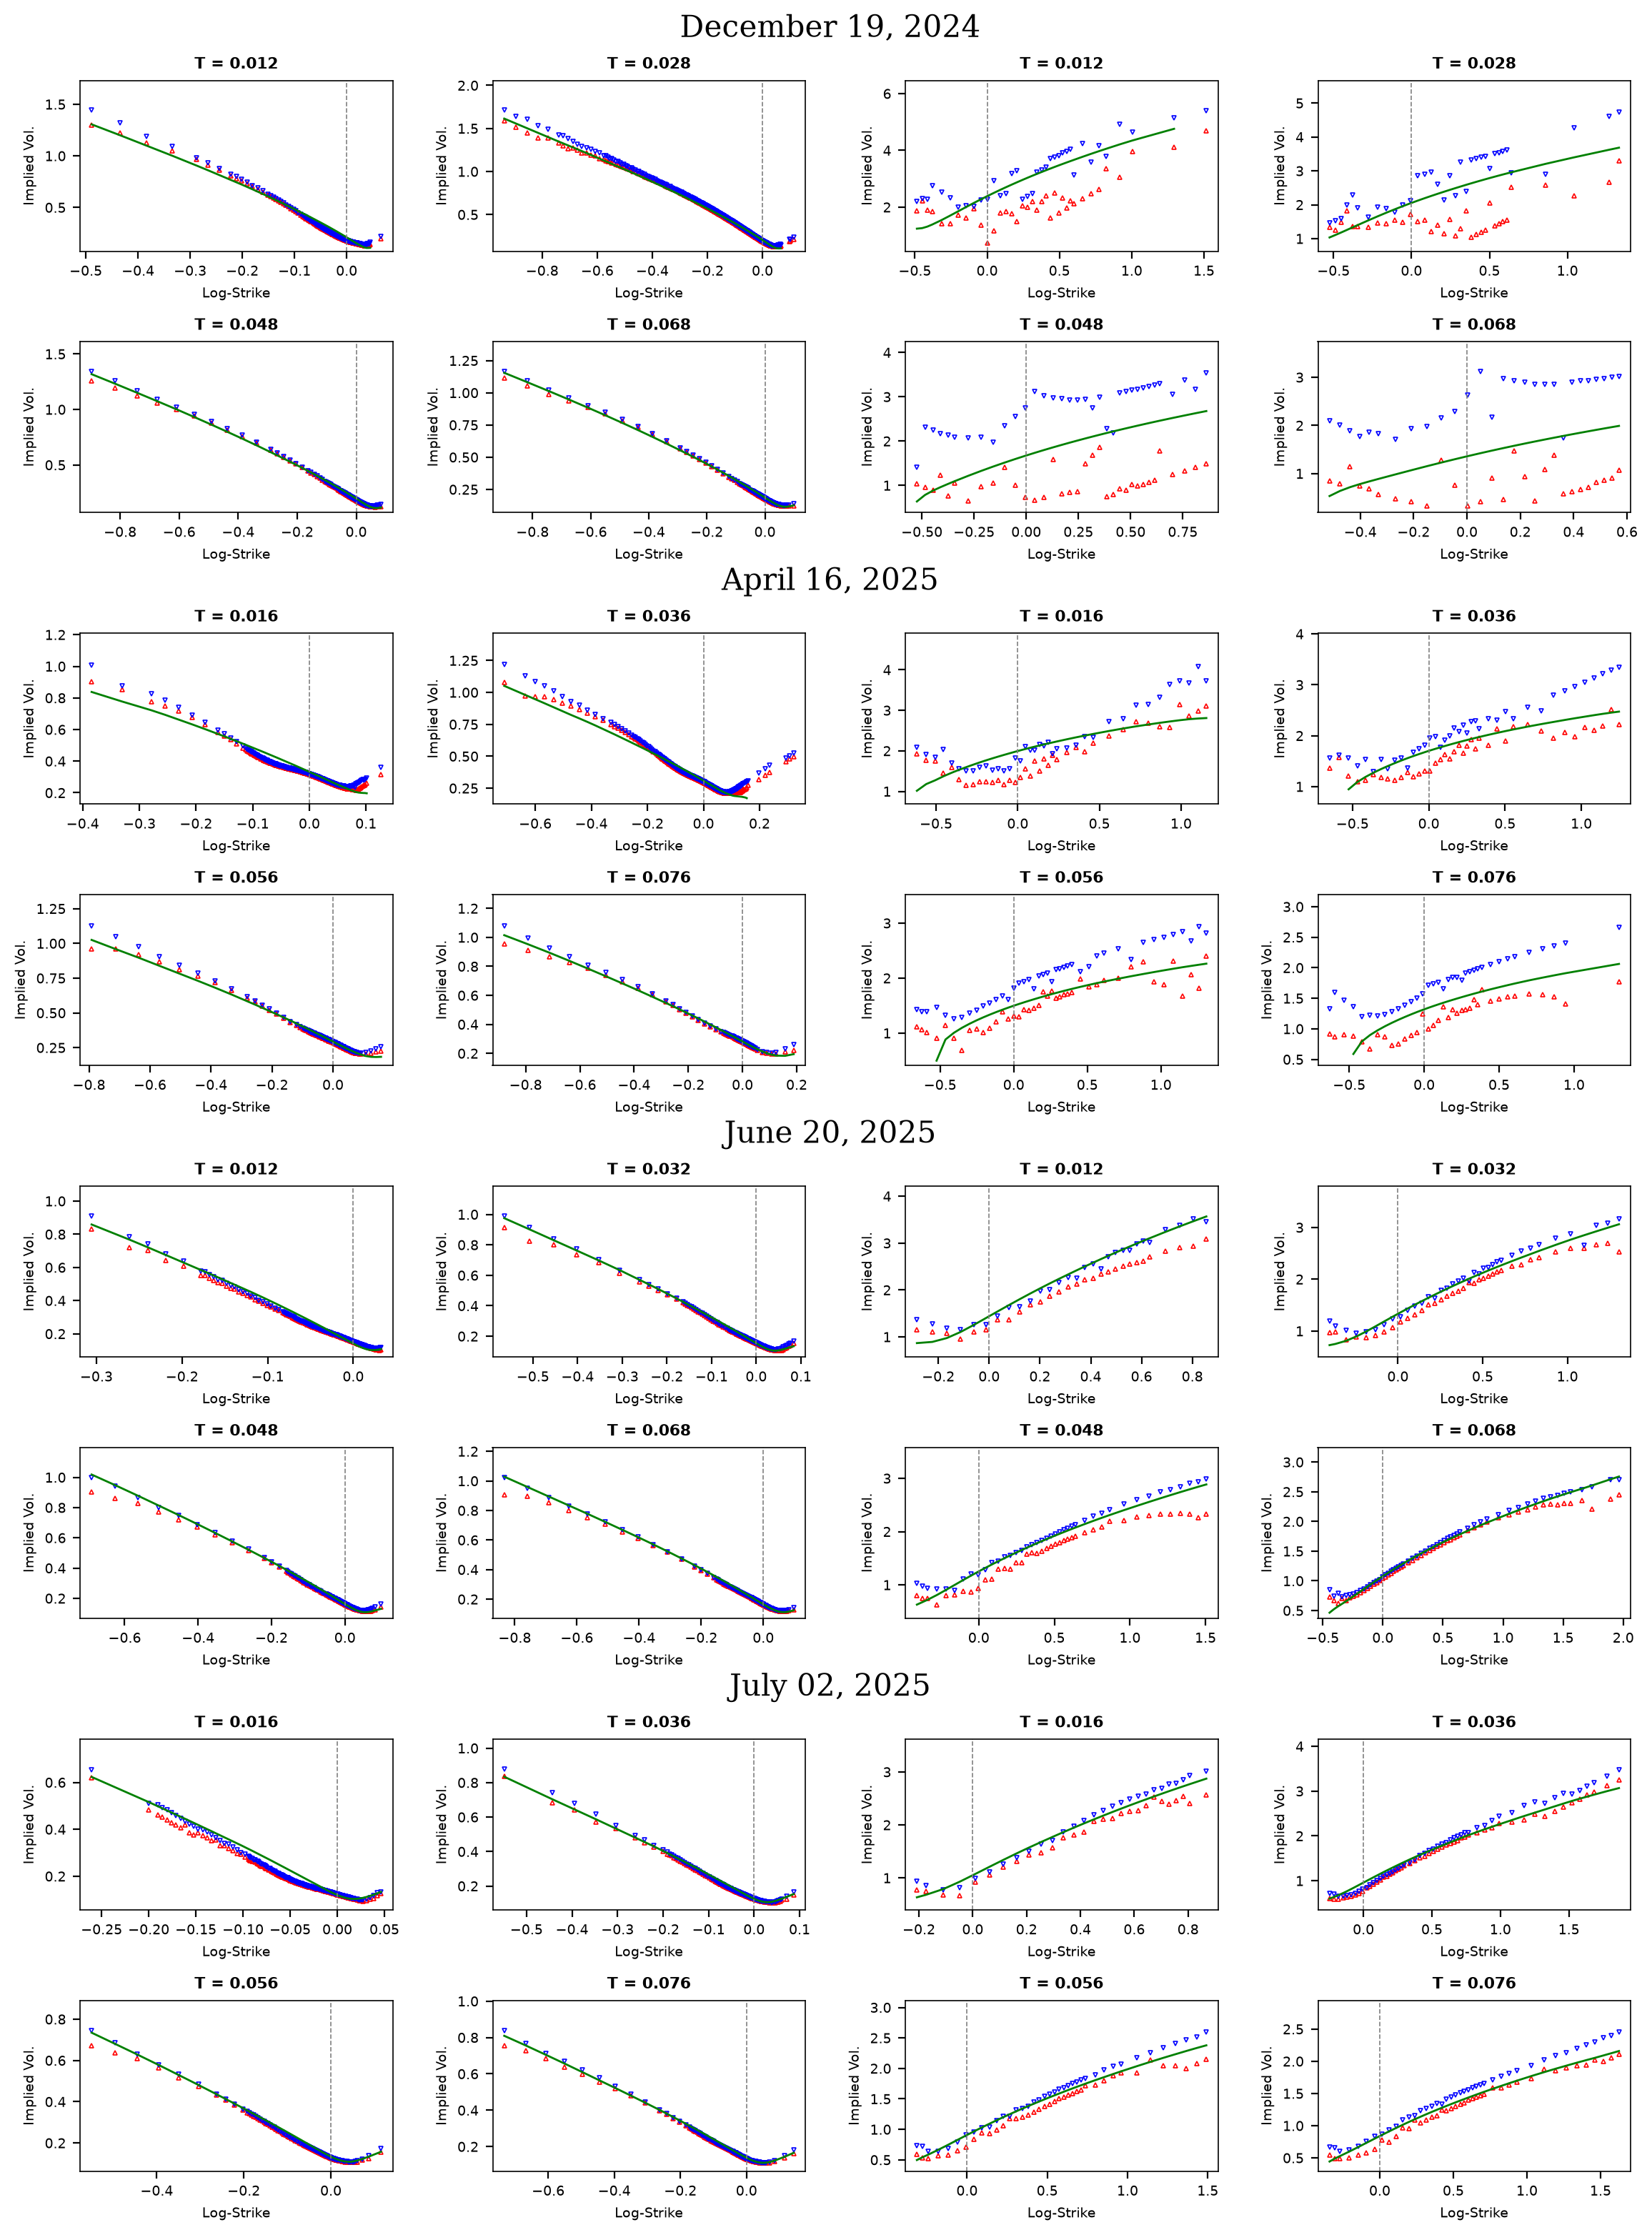

In [6]:
fig = plt.figure(figsize=(14, 19))
outer = fig.add_gridspec(4, 1, hspace=0.28)
for row, date in enumerate(CALIB_DATES):
    sub = outer[row].subgridspec(2, 4, hspace=0.53, wspace=0.32)
    bbox = outer[row].get_position(fig)
    fig.text(
        0.5,
        bbox.y1 + 0.016,
        pd.to_datetime(date).strftime("%B %d, %Y"),
        ha="center",
        fontsize=15,
        fontfamily="serif",
    )
    for offset, asset in ((0, "SPX"), (2, "VIX")):
        part = smiles[(smiles.date == date) & (smiles.asset == asset)]
        for i, (t, d) in enumerate(part.groupby("Texp", sort=True)):
            ax = fig.add_subplot(sub[i // 2, offset + i % 2])
            d = d.sort_values("k")
            ax.plot(d.k, d.Bid, "r^", ms=2.2, fillstyle="none", markeredgewidth=0.6)
            ax.plot(d.k, d.Ask, "bv", ms=2.2, fillstyle="none", markeredgewidth=0.6)
            ax.plot(d.k, d.model, color="green", lw=1)
            include = d.Bid.notna() & (d.Bid > 0)
            kmin, kmax = d.k[include].min(), d.k[include].max()
            kpad = 0.04 * (kmax - kmin)
            ax.set(
                xlim=(kmin - kpad, kmax + kpad),
                ylim=(0.6 * d.Bid[include].min(), 1.2 * d.Ask[include].max()),
                xlabel="Log-Strike",
                ylabel="Implied Vol.",
            )
            ax.set_title(f"T = {t:.3f}", fontweight="bold")
            ax.axvline(0, color="gray", ls="--", lw=0.6)
            ax.axhline(0, color="gray", ls="--", lw=0.6)
plt.show()